# **GEE Connection**

In [ ]:
!pip install -q --upgrade --pre xee
!pip install -q -U geemap

In [ ]:
import ee

In [ ]:
ee.Authenticate()
ee.Initialize(
    project = 'ee-amirhosseinahrari',
    opt_url = 'https://earthengine-highvolume.googleapis.com'
)

# **Study Area**

In [ ]:
import geemap

In [ ]:
map = geemap.Map(basemap = 'SATELLITE')
map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [ ]:
point = map.draw_last_feature.geometry()
point

ee.Geometry({
  "functionInvocationValue": {
    "functionName": "Feature.geometry",
    "arguments": {
      "feature": {
        "functionInvocationValue": {
          "functionName": "Feature",
          "arguments": {
            "geometry": {
              "functionInvocationValue": {
                "functionName": "GeometryConstructors.Point",
                "arguments": {
                  "coordinates": {
                    "constantValue": [
                      52.998047,
                      33.687782
                    ]
                  }
                }
              }
            }
          }
        }
      }
    }
  }
})

In [ ]:
roi = (
    ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017")
    .filterBounds(point)
    .geometry()
)

In [ ]:
map.addLayer(roi, {},'roi')

# **Drought Image Collection**

In [ ]:
spei = (
    ee.ImageCollection("CSIC/SPEI/2_11")
    .filterDate('2000','2025')
    .select('SPEI_06_month')
)

spei

In [ ]:
era = (
    ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR")
    .filterDate('2000','2025')
    .select(
        'temperature_2m',
        'snow_cover',
        'runoff_sum',
        'total_precipitation_sum',
        'volumetric_soil_water_layer_1'
    )
)

era

# **to Xarray**

In [ ]:
from xee import helpers
from shapely.geometry import shape
import xarray as xr

In [ ]:
grid = helpers.fit_geometry(
    geometry = shape(roi.getInfo()),
    grid_crs = 'EPSG:4326',
    grid_scale = (0.5, -0.5)
)

In [ ]:
ds_spei = xr.open_dataset(
    spei,
    engine = 'ee',
    **grid
)

In [ ]:
ds_spei = ds_spei.sortby('time') * 1

In [ ]:
ds_era = xr.open_dataset(
    era,
    engine = 'ee',
    **grid
)

In [ ]:
ds_era = ds_era.sortby('time') * 1

In [ ]:
ds = xr.merge([ds_spei, ds_era])

In [ ]:
ds['drought'] = (ds['SPEI_06_month'] < -0.5).astype(int)

# **Modelling**

In [ ]:
ds = ds.drop('SPEI_06_month')

In [ ]:
df = ds.to_dataframe().dropna()

In [ ]:
x = df.drop('drought', axis = 1)
y = df['drought']

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size = 0.2, random_state = 42
)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
model = RandomForestClassifier(
    n_estimators = 100,
    random_state = 42
)

model.fit(x_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
y_pred = model.predict_proba(x_test)[:,1]

In [ ]:
from sklearn.metrics import roc_auc_score

In [ ]:
print(roc_auc_score(y_test, y_pred))

0.7562956223340895


In [ ]:
df['drought_prob'] = model.predict_proba(df.drop('drought', axis = 1))[:,1]

In [ ]:
dx = df['drought_prob'].to_xarray()

In [ ]:
dx_annual = dx.resample(time = 'YE').mean('time')

# **Clipping**

In [ ]:
roi_gdf = geemap.ee_to_gdf(ee.FeatureCollection(roi))

In [ ]:
!pip install -q rioxarray
import rioxarray

In [ ]:
dx_annual_proj = dx_annual.rio.write_crs('EPSG:4326')

In [ ]:
dx_clip = dx_annual_proj.rio.clip(roi_gdf.geometry, roi_gdf.crs)

# **Visualization**

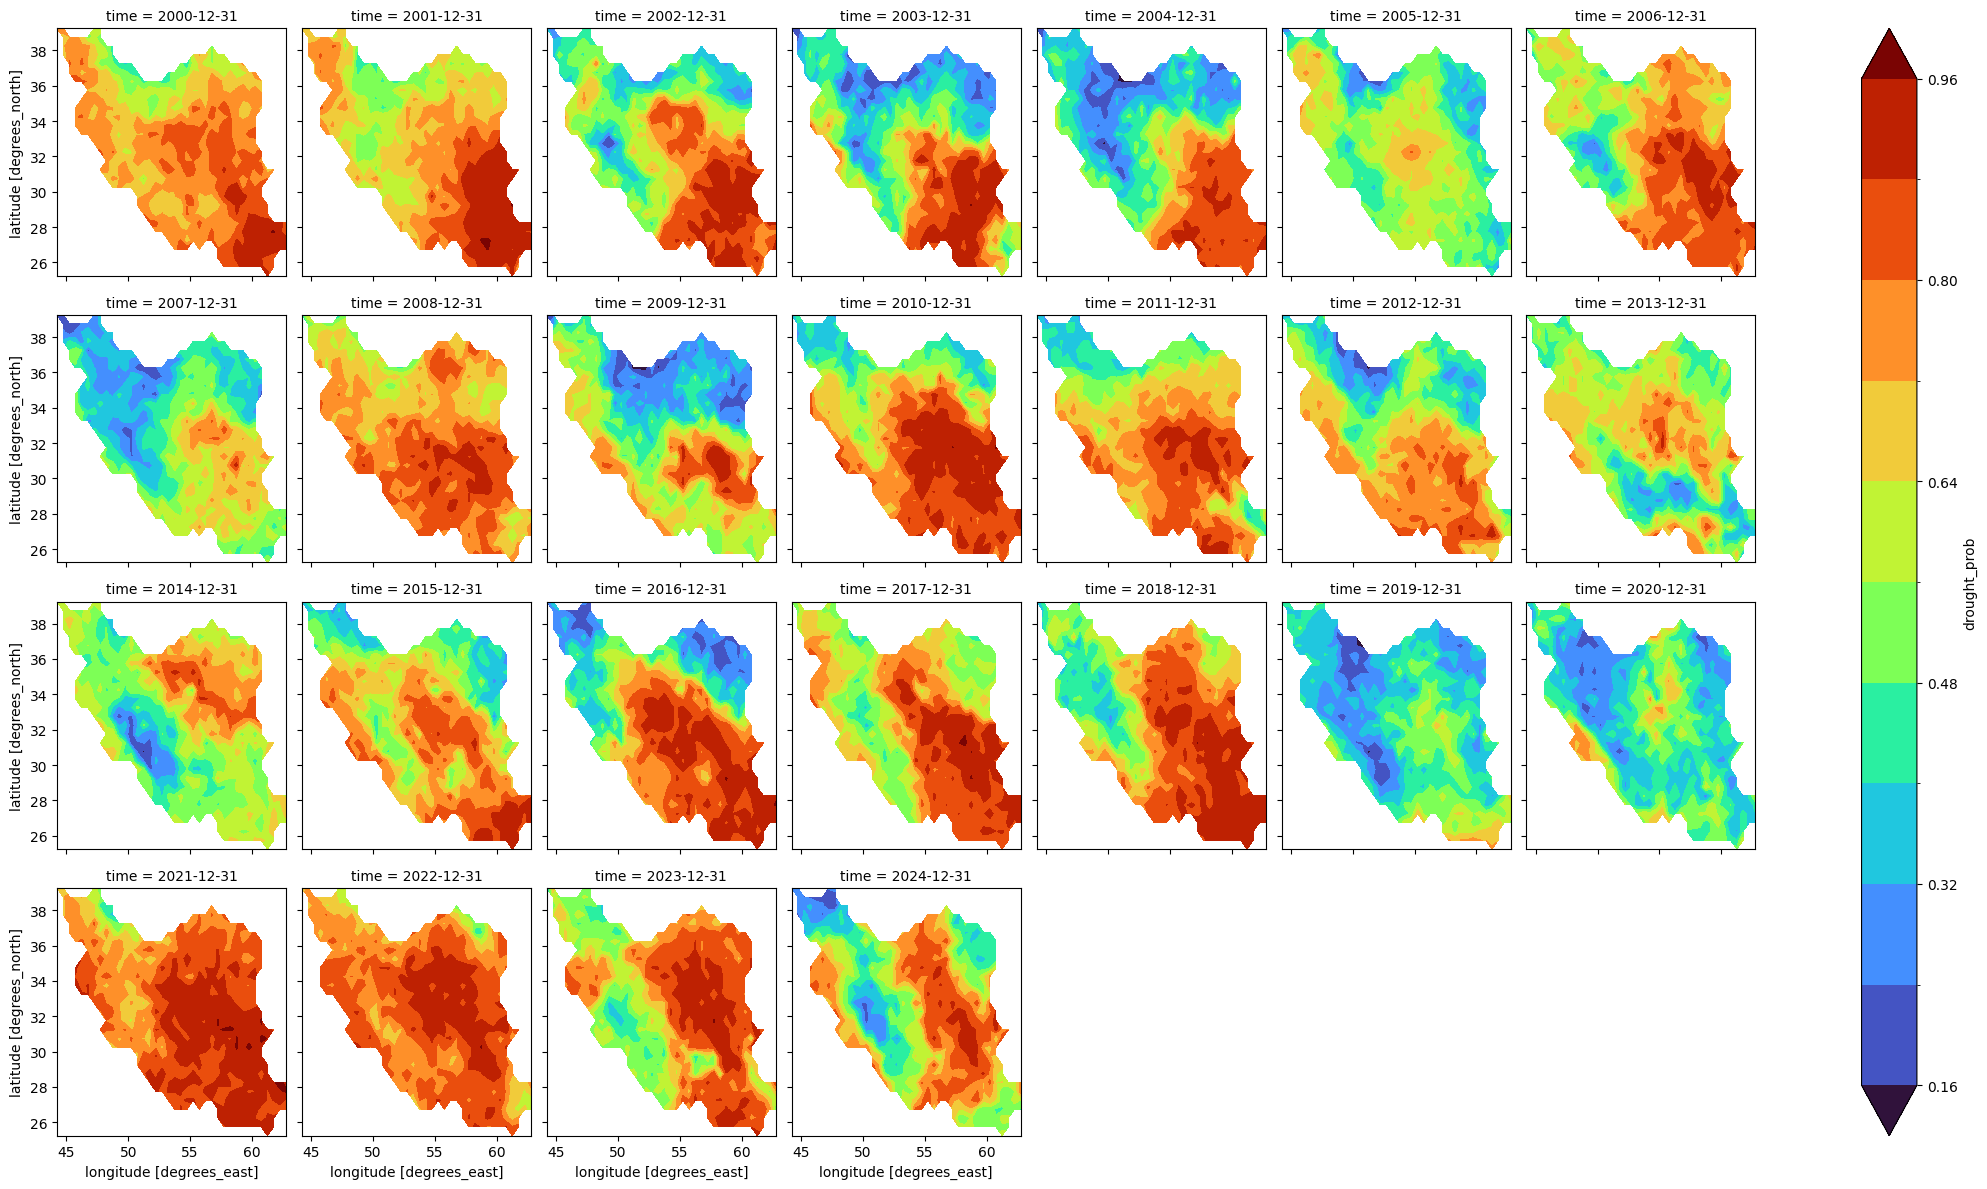

In [ ]:
dx_clip.plot.contourf(
    col = 'time',
    col_wrap = 7,
    cmap = 'turbo',
    levels = 10,
    robust = True
)

In [ ]:
point_val = dx.sel(
    x = 48.57046190314686,
    y = 31.36232439130279,
    method = 'nearest'
).to_dataframe()['drought_prob']

In [ ]:
point_annual = point_val.resample('YE').mean('time')

<Axes: xlabel='time'>

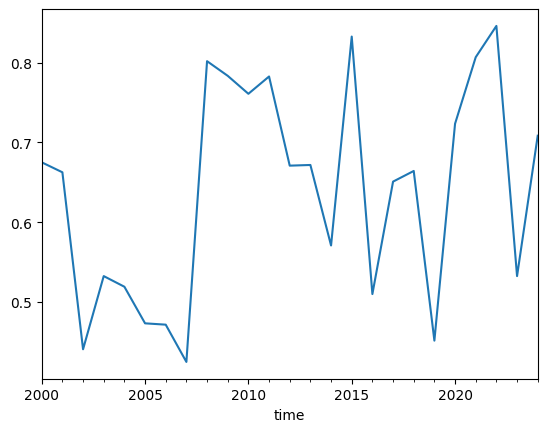

In [ ]:
point_annual.plot()